# Task 2: Support Ticket Classification
**Future Interns - Machine Learning Track**

**Goal:** automatically (1) classify support tickets into a category and (2) tag a priority level (High / Medium / Low), so support teams can respond faster.

**Workflow:** load -> text cleaning & tokenization -> TF-IDF features -> category model -> priority model -> evaluation -> live prediction function.

In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings("ignore")

## 1. Load data

In [2]:
df = pd.read_csv("data/support_tickets.csv")
print(df.shape)
print(df["category"].value_counts(), "\n")
print(df["priority"].value_counts())
df.head()

(3000, 4)
category
Account Access     641
Technical Issue    624
Billing            587
General Inquiry    579
Shipping           569
Name: count, dtype: int64 

priority
Low       1128
Medium    1078
High       794
Name: count, dtype: int64


,ticket_id,text,category,priority
0,T00001,"dear support, i want to delete my account perm...",Account Access,Low
1,T00002,"hi team, please update the billing address on ...",Billing,Medium
2,T00003,"hi team, the coupon code did not apply at chec...",Billing,Medium
3,T00004,"dear support, i was charged twice for my subsc...",Billing,Medium
4,T00005,"good morning, is there a mobile app available ...",General Inquiry,Medium


## 2. Text cleaning & tokenization

In [3]:
# keep a few words that matter for priority even though they look like stop words
keep = {"not", "no", "cannot", "never"}
stop = set(ENGLISH_STOP_WORDS) - keep

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)      # remove punctuation
    tokens = [t for t in text.split() if t not in stop and len(t) > 1]  # tokenize + stopwords
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(clean_text)
df[["text", "clean_text"]].head()

,text,clean_text
0,"dear support, i want to delete my account perm...",dear support want delete account permanently t...
1,"hi team, please update the billing address on ...",hi team update billing address invoice kindly ...
2,"hi team, the coupon code did not apply at chec...",hi team coupon code did not apply checkout pai...
3,"dear support, i was charged twice for my subsc...",dear support charged twice subscription month ...
4,"good morning, is there a mobile app available ...",good morning mobile app available attached scr...


## 3. Train / test split

In [4]:
X_train, X_test, yc_train, yc_test, yp_train, yp_test = train_test_split(
    df["clean_text"], df["category"], df["priority"],
    test_size=0.2, random_state=42, stratify=df["category"])
print(len(X_train), "train |", len(X_test), "test")

2400 train | 600 test


## 4. Ticket category classification
Two models are compared on the same TF-IDF features.

In [5]:
def make_pipe(clf):
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)), ("clf", clf)])

cat_models = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=1000)),
    "Linear SVM": make_pipe(LinearSVC()),
}
rows = []
for name, pipe in cat_models.items():
    pipe.fit(X_train, yc_train)
    p = pipe.predict(X_test)
    rows.append([name, accuracy_score(yc_test, p), f1_score(yc_test, p, average="macro")])

cat_results = pd.DataFrame(rows, columns=["model", "accuracy", "macro F1"]).set_index("model").round(3)
cat_results

,accuracy,macro F1
model,,
Logistic Regression,0.988,0.989
Linear SVM,0.988,0.989


Best category model: Logistic Regression 

                 precision    recall  f1-score   support

 Account Access       0.98      0.98      0.98       128
        Billing       0.99      0.99      0.99       117
General Inquiry       1.00      0.99      1.00       116
       Shipping       0.98      1.00      0.99       114
Technical Issue       0.98      0.98      0.98       125

       accuracy                           0.99       600
      macro avg       0.99      0.99      0.99       600
   weighted avg       0.99      0.99      0.99       600



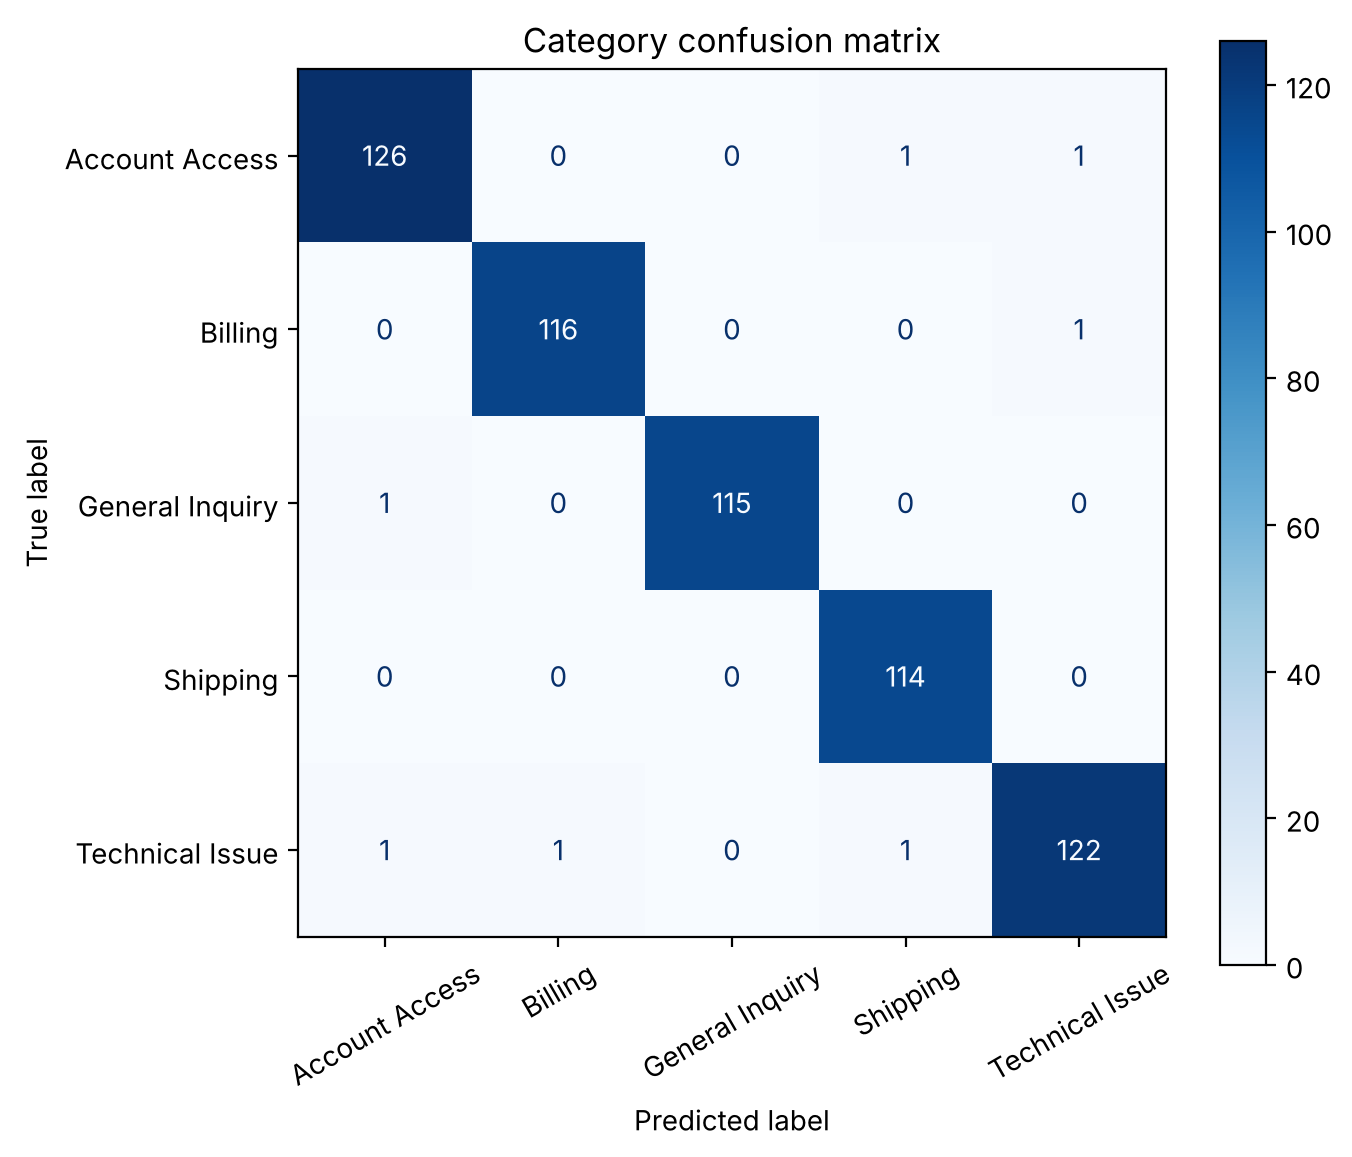

In [6]:
best_cat_name = cat_results["macro F1"].idxmax()
cat_model = cat_models[best_cat_name]
cat_pred = cat_model.predict(X_test)
print("Best category model:", best_cat_name, "\n")
print(classification_report(yc_test, cat_pred))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(yc_test, cat_pred, xticks_rotation=30, cmap="Blues", ax=ax)
ax.set_title("Category confusion matrix")
plt.savefig("outputs/01_category_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Priority tagging (High / Medium / Low)
Priority is handled with two layers:
1. **ML model** trained on the ticket text (urgency wording, issue type).
2. **Business rule override:** tickets containing strong urgency phrases are always escalated to High, because missing a truly urgent ticket is more costly than over-escalating one.

Priority model accuracy: 0.89
              precision    recall  f1-score   support

        High       0.94      0.90      0.92       144
         Low       0.79      0.97      0.87       224
      Medium       0.99      0.80      0.89       232

    accuracy                           0.89       600
   macro avg       0.91      0.89      0.89       600
weighted avg       0.91      0.89      0.89       600



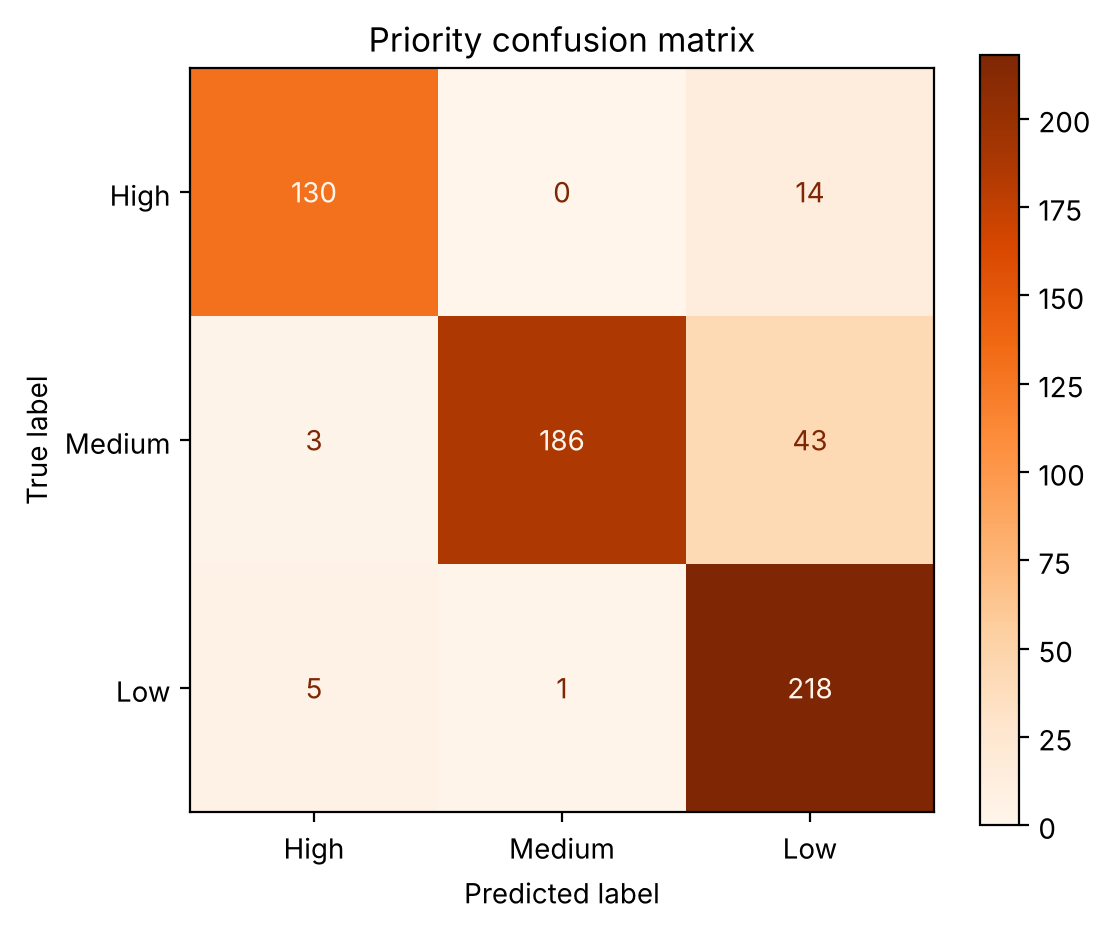

In [7]:
prio_model = make_pipe(LogisticRegression(max_iter=1000, class_weight="balanced"))
prio_model.fit(X_train, yp_train)
prio_pred = prio_model.predict(X_test)

print("Priority model accuracy:", round(accuracy_score(yp_test, prio_pred), 3))
print(classification_report(yp_test, prio_pred))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(yp_test, prio_pred, labels=["High", "Medium", "Low"], cmap="Oranges", ax=ax)
ax.set_title("Priority confusion matrix")
plt.savefig("outputs/02_priority_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

In [8]:
urgent_words = ["urgent", "immediately", "asap", "critical", "escalat", "blocked", "losing money"]

def tag_priority(raw_text):
    t = raw_text.lower()
    if any(w in t for w in urgent_words):
        return "High", "rule: urgency keyword"
    return prio_model.predict([clean_text(raw_text)])[0], "model"

def analyze_ticket(raw_text):
    c = clean_text(raw_text)
    category = cat_model.predict([c])[0]
    priority, source = tag_priority(raw_text)
    return {"category": category, "priority": priority, "priority_source": source}

# how good is the combined (model + rule) priority on the test tickets?
raw_test = df.loc[X_test.index, "text"]
combined = [tag_priority(t)[0] for t in raw_test]
print("Combined priority accuracy:", round(accuracy_score(yp_test, combined), 3))
print("High-priority recall (model only):", round(((prio_pred == "High") & (yp_test == "High")).sum() / (yp_test == "High").sum(), 3))
print("High-priority recall (model+rule):", round((((pd.Series(combined, index=yp_test.index)) == "High") & (yp_test == "High")).sum() / (yp_test == "High").sum(), 3))

Combined priority accuracy: 0.89
High-priority recall (model only): 0.903
High-priority recall (model+rule): 0.903


## 6. Try it on new tickets

In [9]:
samples = [
    "My payment went through twice and I need a refund ASAP",
    "App keeps crashing on startup, my whole team is blocked",
    "Do you have a student discount for the premium plan?",
    "I cannot log in, password reset email is not coming",
    "My parcel is delayed, please look into this soon",
]
pd.DataFrame([{"ticket": s, **analyze_ticket(s)} for s in samples])

,ticket,category,priority,priority_source
0,My payment went through twice and I need a ref...,Billing,High,rule: urgency keyword
1,"App keeps crashing on startup, my whole team i...",Technical Issue,High,rule: urgency keyword
2,Do you have a student discount for the premium...,General Inquiry,Low,model
3,"I cannot log in, password reset email is not c...",Account Access,Low,model
4,"My parcel is delayed, please look into this soon",Shipping,Medium,model


## 7. Support analytics

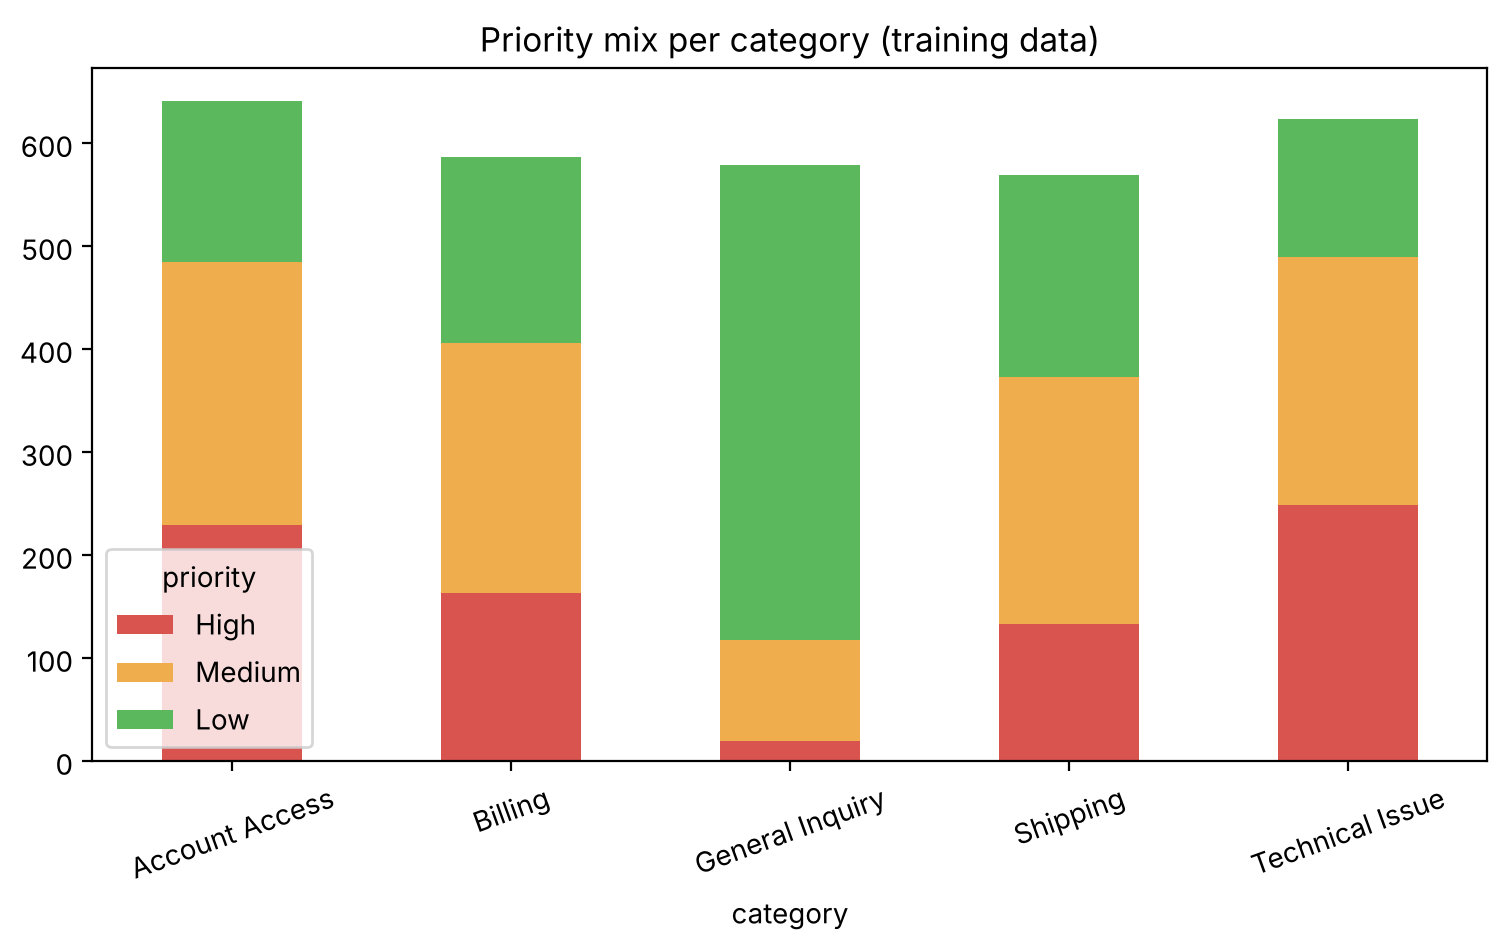

priority,High,Medium,Low
category,,,
Account Access,229,256,156
Billing,163,243,181
General Inquiry,20,98,461
Shipping,133,240,196
Technical Issue,249,241,134


In [10]:
ct = pd.crosstab(df["category"], df["priority"])[["High", "Medium", "Low"]]
ct.plot(kind="bar", stacked=True, figsize=(9, 4.5), color=["#d9534f", "#f0ad4e", "#5cb85c"])
plt.title("Priority mix per category (training data)")
plt.xticks(rotation=20)
plt.savefig("outputs/03_priority_by_category.png", dpi=120, bbox_inches="tight")
plt.show()
ct

## Conclusion
- The category model separates the five ticket types well; remaining errors come mostly from deliberately noisy labels (3% simulated mis-tagging).
- Priority is harder than category because urgency is partly subjective, so a rule layer protects against missing urgent tickets.
- **Business impact:** tickets can be auto-routed to the right team and sorted so High priority ones are answered first.
- **Next steps:** train on real historical tickets, add customer plan/tier as a feature, and move to transformer embeddings for subtler wording.